In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import joblib

from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
DATA_DIR = Path("cbb_data")
MODEL_DIR = Path("cbb_models")

TEST_SEASONS = [2025, 2026]

TARGET = "target_home_margin"
MARKET = "market_home_margin"

In [3]:
# Load the two trained models.
ridge_model = joblib.load(
    MODEL_DIR / "ridge_model.joblib"
)

xgb_model = joblib.load(
    MODEL_DIR / "xgboost_model.joblib"
)

# Load each model's selected feature names.
with open(MODEL_DIR / "linear_features.json") as f:
    ridge_features = json.load(f)

with open(MODEL_DIR / "xgboost_features.json") as f:
    xgb_features = json.load(f)

print("Ridge features:", len(ridge_features))
print("XGBoost features:", len(xgb_features))

print("\nRidge model:")
print(ridge_model)

print("\nXGBoost model:")
print(xgb_model)

Ridge features: 25
XGBoost features: 30

Ridge model:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()), ('ridge', Ridge(alpha=100))])

XGBoost model:
XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type='gain', interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=-1, num_parallel_tree=None, ...)


In [4]:
def load_season(year):
    filename = DATA_DIR / f"games_{year-1}_{year}.csv"
    return pd.read_csv(filename)

test_frames = []

for year in TEST_SEASONS:
    df = load_season(year)

    # Preserve the season for later failure analysis.
    df["test_season"] = year

    test_frames.append(df)

test_df = pd.concat(
    test_frames,
    ignore_index=True
)

print("Total test games:", len(test_df))

display(
    test_df.groupby("test_season").size()
)

Total test games: 11514


test_season
2025    5762
2026    5752
dtype: int64

In [5]:
required_columns = set(
    ridge_features + xgb_features + [TARGET, MARKET]
)

missing_columns = required_columns - set(test_df.columns)

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("All required columns are present.")

# Verify no missing target values.
assert test_df[TARGET].notna().all()

# Check missingness in selected features.
print("\nRidge feature missingness:")
print(
    test_df[ridge_features]
    .isna()
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

print("\nXGBoost feature missingness:")
print(
    test_df[xgb_features]
    .isna()
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

All required columns are present.

Ridge feature missingness:
diff_avg_sor           0.072173
diff_last5_sor         0.072173
diff_avg_sos_margin    0.072173
home_avg_sos_margin    0.062359
diff_avg_pace          0.042383
diff_avg_oreb_pct      0.038214
diff_avg_fg3_pct       0.038214
diff_last5_blocks      0.038214
diff_avg_blocks        0.038214
diff_avg_assists       0.038214
dtype: float64

XGBoost feature missingness:
diff_avg_sos_margin      0.072173
diff_avg_sor             0.072173
diff_last5_sos_margin    0.072173
diff_last5_sos_win       0.072173
diff_avg_sos_win         0.072173
home_avg_sos_margin      0.062359
home_avg_sos_win         0.062359
home_avg_sor             0.062359
diff_avg_assists         0.038214
diff_avg_fg3_pct         0.038214
dtype: float64


In [6]:
# Predict home-team scoring margin.
test_df["ridge_prediction"] = ridge_model.predict(
    test_df[ridge_features]
)

test_df["xgb_prediction"] = xgb_model.predict(
    test_df[xgb_features]
)

# Zero-margin baseline.
test_df["zero_prediction"] = 0.0

# Verify predictions are finite.
assert np.isfinite(test_df["ridge_prediction"]).all()
assert np.isfinite(test_df["xgb_prediction"]).all()

print("Predictions generated successfully.")

Predictions generated successfully.


In [7]:
# Select identifying columns if available.
display_columns = [
    col for col in [
        "test_season",
        "date",
        "home_team",
        "away_team",
        "ridge_prediction",
        "xgb_prediction",
        "market_home_margin"
    ]
    if col in test_df.columns
]

display(
    test_df[display_columns].head(15).round(2)
)

print("\nPrediction summary:")

display(
    test_df[
        ["ridge_prediction", "xgb_prediction"]
    ].describe().round(2)
)

,test_season,date,home_team,away_team,ridge_prediction,xgb_prediction,market_home_margin
0,2025,2024-11-04T17:00:00.000Z,Southern Illinois,Charleston,10.62,4.23,-3.5
1,2025,2024-11-04T20:00:00.000Z,Santa Clara,Saint Louis,10.62,4.23,1.5
2,2025,2024-11-04T21:00:00.000Z,Stanford,Denver,14.09,14.48,17.5
3,2025,2024-11-04T22:00:00.000Z,Harvard,Marist,14.09,14.48,2.5
4,2025,2024-11-04T22:00:00.000Z,Liberty,Valparaiso,10.62,4.23,10.5
5,2025,2024-11-04T22:30:00.000Z,Temple,Sacred Heart,14.09,14.48,13.5
6,2025,2024-11-04T23:00:00.000Z,Purdue,Texas A&M-Corpus Christi,14.09,14.48,25.5
7,2025,2024-11-04T23:00:00.000Z,South Dakota State,McNeese,10.62,4.23,-10.5
8,2025,2024-11-04T23:30:00.000Z,Delaware,Bucknell,14.09,14.48,4.5
9,2025,2024-11-04T23:30:00.000Z,App State,Miami (OH),14.09,14.48,6.5



Prediction summary:


,ridge_prediction,xgb_prediction
count,11514.00,11514.00
mean,5.34,5.40
std,8.10,8.73
min,-24.64,-23.13
25%,0.16,-0.32
50%,4.38,4.47
75%,9.57,10.46
max,64.20,43.47


In [8]:
OUTPUT_DIR = Path("cbb_final_results")
OUTPUT_DIR.mkdir(exist_ok=True)

test_df.to_csv(
    OUTPUT_DIR / "test_predictions.csv",
    index=False
)

print("Saved test_predictions.csv")

Saved test_predictions.csv


In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

models = {
    "Zero Margin": "zero_prediction",
    "Ridge": "ridge_prediction",
    "XGBoost": "xgb_prediction"
}

results = []

for name, column in models.items():
    mae = mean_absolute_error(
        test_df[TARGET],
        test_df[column]
    )

    rmse = np.sqrt(
        mean_squared_error(
            test_df[TARGET],
            test_df[column]
        )
    )

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "Games": len(test_df)
    })

test_results = pd.DataFrame(results)

display(test_results.round(3))

,Model,MAE,RMSE,Games
0,Zero Margin,12.308,15.802,11514
1,Ridge,9.570,12.254,11514
2,XGBoost,9.435,12.039,11514


In [10]:
market_test = test_df[
    test_df[MARKET].notna()
].copy()

market_models = {
    "Zero Margin": "zero_prediction",
    "Ridge": "ridge_prediction",
    "XGBoost": "xgb_prediction",
    "Sportsbook": MARKET
}

market_results = []

for name, column in market_models.items():

    mae = mean_absolute_error(
        market_test[TARGET],
        market_test[column]
    )

    rmse = np.sqrt(
        mean_squared_error(
            market_test[TARGET],
            market_test[column]
        )
    )

    market_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "Games": len(market_test)
    })

market_results = pd.DataFrame(market_results)

display(market_results.round(3))

,Model,MAE,RMSE,Games
0,Zero Margin,12.337,15.848,11161
1,Ridge,9.560,12.246,11161
2,XGBoost,9.422,12.021,11161
3,Sportsbook,8.896,11.304,11161


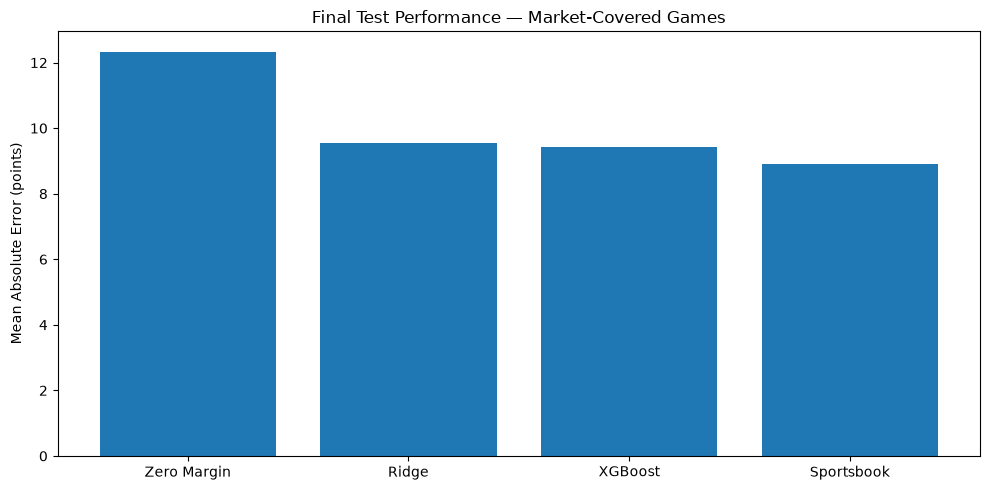

In [11]:
plt.figure(figsize=(10, 5))

plt.bar(
    market_results["Model"],
    market_results["MAE"]
)

plt.ylabel("Mean Absolute Error (points)")
plt.title("Final Test Performance — Market-Covered Games")

plt.tight_layout()
plt.show()

In [12]:
season_results = []

for season, group in test_df.groupby("test_season"):

    for name, column in models.items():

        season_results.append({
            "Season": season,
            "Model": name,
            "Games": len(group),
            "MAE": mean_absolute_error(
                group[TARGET],
                group[column]
            )
        })

season_results = pd.DataFrame(season_results)

display(
    season_results.pivot(
        index="Season",
        columns="Model",
        values="MAE"
    ).round(3)
)

Model,Ridge,XGBoost,Zero Margin
Season,,,
2025,9.559,9.374,12.188
2026,9.580,9.496,12.428


# More Analysis

In [13]:
# Calculate absolute errors for each model.
test_df["ridge_abs_error"] = (
    test_df[TARGET] - test_df["ridge_prediction"]
).abs()

test_df["xgb_abs_error"] = (
    test_df[TARGET] - test_df["xgb_prediction"]
).abs()

# Average number of previous games played by both teams.
test_df["avg_games_played"] = (
    test_df["home_games_played"]
    + test_df["away_games_played"]
) / 2

In [14]:
# Group games by how much current-season information exists.
test_df["experience_group"] = pd.cut(
    test_df["avg_games_played"],
    bins=[-1, 3, 8, 15, 25, np.inf],
    labels=[
        "0–3 games",
        "4–8 games",
        "9–15 games",
        "16–25 games",
        "26+ games"
    ]
)

experience_results = (
    test_df.groupby("experience_group", observed=True)
    .agg(
        Games=("xgb_abs_error", "size"),
        Ridge_MAE=("ridge_abs_error", "mean"),
        XGBoost_MAE=("xgb_abs_error", "mean")
    )
)

display(experience_results.round(3))

,Games,Ridge_MAE,XGBoost_MAE
experience_group,,,
0–3 games,1359,11.899,11.370
4–8 games,1817,10.309,10.232
9–15 games,2581,9.167,9.125
16–25 games,3638,8.925,8.874
26+ games,2119,9.039,8.852


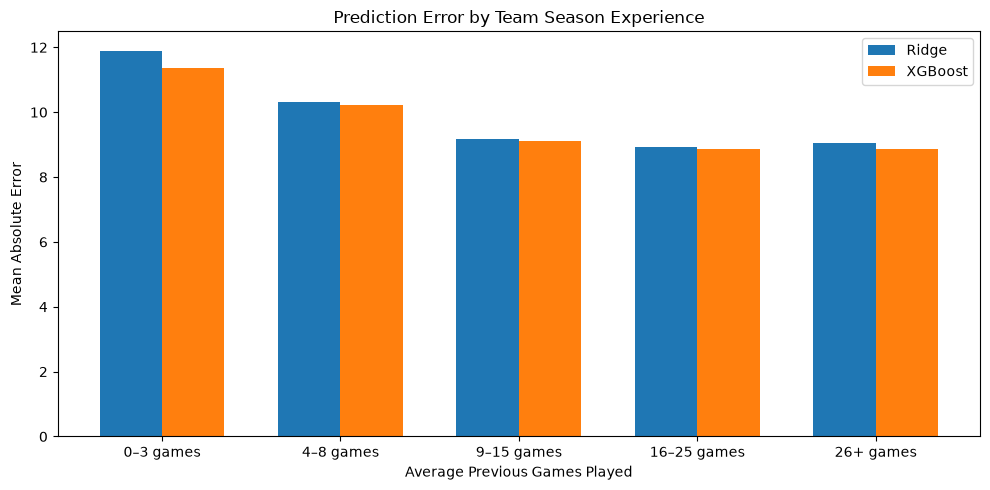

In [16]:
plt.figure(figsize=(10, 5))

x = np.arange(len(experience_results))
width = 0.35

plt.bar(
    x - width/2,
    experience_results["Ridge_MAE"],
    width,
    label="Ridge"
)

plt.bar(
    x + width/2,
    experience_results["XGBoost_MAE"],
    width,
    label="XGBoost"
)

plt.xticks(
    x,
    experience_results.index.astype(str)
)

plt.xlabel("Average Previous Games Played")
plt.ylabel("Mean Absolute Error")
plt.title("Prediction Error by Team Season Experience")

plt.legend()
plt.tight_layout()
plt.show()

In [17]:
rng = np.random.default_rng(42)

def bootstrap_mae_ci(errors, n_boot=2000):
    errors = np.asarray(errors)

    boot_means = []

    for _ in range(n_boot):
        sample = rng.choice(
            errors,
            size=len(errors),
            replace=True
        )

        boot_means.append(sample.mean())

    return np.percentile(boot_means, [2.5, 97.5])


slice_results = []

for group, data in test_df.groupby(
    "experience_group", observed=True
):

    lower, upper = bootstrap_mae_ci(
        data["xgb_abs_error"]
    )

    slice_results.append({
        "Group": group,
        "Games": len(data),
        "XGBoost MAE": data["xgb_abs_error"].mean(),
        "CI Lower": lower,
        "CI Upper": upper
    })

slice_results = pd.DataFrame(slice_results)

display(
    slice_results.sort_values(
        "XGBoost MAE",
        ascending=False
    ).round(3)
)

,Group,Games,XGBoost MAE,CI Lower,CI Upper
0,0–3 games,1359,11.370,10.885,11.858
1,4–8 games,1817,10.232,9.858,10.606
2,9–15 games,2581,9.125,8.852,9.403
3,16–25 games,3638,8.874,8.651,9.112
4,26+ games,2119,8.852,8.569,9.133


In [18]:
# Only games with historical betting lines.
market_slice = test_df[
    test_df[MARKET].notna()
].copy()

# Sportsbook absolute prediction error.
market_slice["market_abs_error"] = (
    market_slice[TARGET] - market_slice[MARKET]
).abs()

experience_market_results = (
    market_slice.groupby("experience_group", observed=True)
    .agg(
        Games=("market_abs_error", "size"),
        XGBoost_MAE=("xgb_abs_error", "mean"),
        Sportsbook_MAE=("market_abs_error", "mean")
    )
)

# How far behind the sportsbook is XGBoost?
experience_market_results["XGB_Minus_Market"] = (
    experience_market_results["XGBoost_MAE"]
    - experience_market_results["Sportsbook_MAE"]
)

display(experience_market_results.round(3))

,Games,XGBoost_MAE,Sportsbook_MAE,XGB_Minus_Market
experience_group,,,,
0–3 games,1353,11.349,9.186,2.164
4–8 games,1807,10.248,9.691,0.558
9–15 games,2579,9.127,8.709,0.417
16–25 games,3314,8.780,8.633,0.147
26+ games,2108,8.849,8.669,0.180


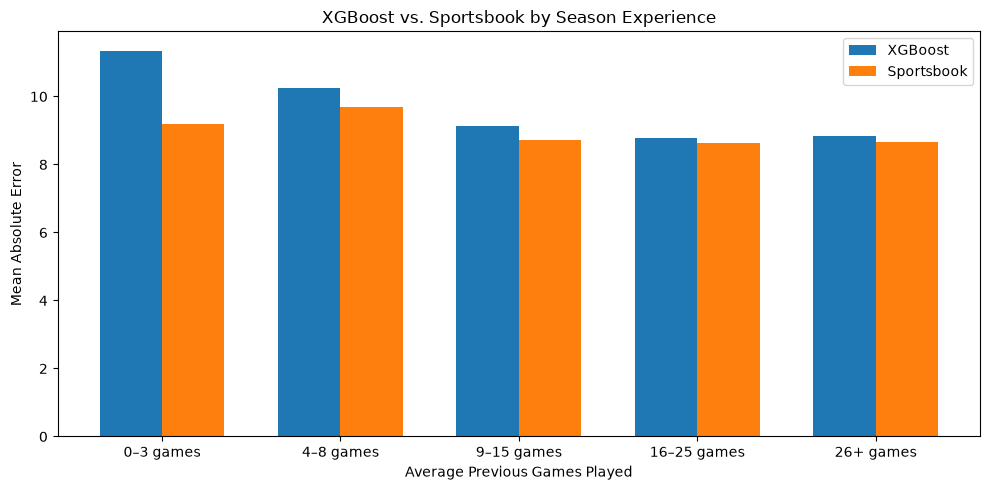

In [19]:
plt.figure(figsize=(10, 5))

x = np.arange(len(experience_market_results))
width = 0.35

plt.bar(
    x - width/2,
    experience_market_results["XGBoost_MAE"],
    width,
    label="XGBoost"
)

plt.bar(
    x + width/2,
    experience_market_results["Sportsbook_MAE"],
    width,
    label="Sportsbook"
)

plt.xticks(
    x,
    experience_market_results.index.astype(str)
)

plt.xlabel("Average Previous Games Played")
plt.ylabel("Mean Absolute Error")
plt.title("XGBoost vs. Sportsbook by Season Experience")

plt.legend()
plt.tight_layout()
plt.show()

In [20]:
# Only games with historical sportsbook lines.
matchup_df = test_df[test_df[MARKET].notna()].copy()

# Absolute spread measures how uneven the matchup is expected to be.
matchup_df["absolute_spread"] = matchup_df[MARKET].abs()

matchup_df["spread_group"] = pd.cut(
    matchup_df["absolute_spread"],
    bins=[-0.01, 5, 10, 15, 20, np.inf],
    labels=["0–5", "5–10", "10–15", "15–20", "20+"]
)

# Absolute prediction errors.
matchup_df["market_abs_error"] = (
    matchup_df[TARGET] - matchup_df[MARKET]
).abs()

spread_results = (
    matchup_df.groupby("spread_group", observed=True)
    .agg(
        Games=("xgb_abs_error", "size"),
        Ridge_MAE=("ridge_abs_error", "mean"),
        XGBoost_MAE=("xgb_abs_error", "mean"),
        Sportsbook_MAE=("market_abs_error", "mean")
    )
)

display(spread_results.round(3))

,Games,Ridge_MAE,XGBoost_MAE,Sportsbook_MAE
spread_group,,,,
0–5,4616,9.266,9.203,8.835
5–10,3359,9.215,9.154,8.745
10–15,1583,9.003,8.948,8.572
15–20,711,9.963,9.679,8.975
20+,892,13.049,12.206,10.286


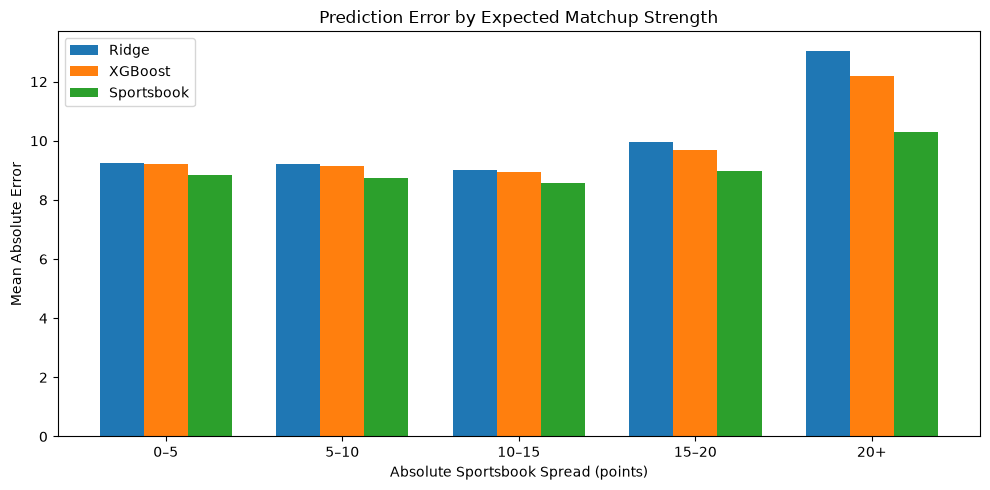

In [21]:
plt.figure(figsize=(10, 5))

x = np.arange(len(spread_results))
width = 0.25

plt.bar(
    x - width,
    spread_results["Ridge_MAE"],
    width,
    label="Ridge"
)

plt.bar(
    x,
    spread_results["XGBoost_MAE"],
    width,
    label="XGBoost"
)

plt.bar(
    x + width,
    spread_results["Sportsbook_MAE"],
    width,
    label="Sportsbook"
)

plt.xticks(x, spread_results.index.astype(str))

plt.xlabel("Absolute Sportsbook Spread (points)")
plt.ylabel("Mean Absolute Error")
plt.title("Prediction Error by Expected Matchup Strength")

plt.legend()
plt.tight_layout()
plt.show()

In [22]:
spread_ci_results = []

for group, data in matchup_df.groupby(
    "spread_group", observed=True
):
    lower, upper = bootstrap_mae_ci(
        data["xgb_abs_error"]
    )

    spread_ci_results.append({
        "Spread Group": group,
        "Games": len(data),
        "XGBoost MAE": data["xgb_abs_error"].mean(),
        "CI Lower": lower,
        "CI Upper": upper
    })

spread_ci_results = pd.DataFrame(spread_ci_results)

display(
    spread_ci_results.sort_values(
        "XGBoost MAE",
        ascending=False
    ).round(3)
)

,Spread Group,Games,XGBoost MAE,CI Lower,CI Upper
4,20+,892,12.206,11.603,12.803
3,15–20,711,9.679,9.124,10.228
0,0–5,4616,9.203,8.995,9.403
1,5–10,3359,9.154,8.905,9.405
2,10–15,1583,8.948,8.593,9.291


In [23]:
# Use games with available sportsbook lines.
combined_slice = matchup_df.copy()

# Flag games with a large expected margin.
combined_slice["heavy_favorite"] = (
    combined_slice["absolute_spread"] >= 20
)

# Compare experience groups and heavy-favorite status.
combined_results = (
    combined_slice.groupby(
        ["experience_group", "heavy_favorite"],
        observed=True
    )
    .agg(
        Games=("xgb_abs_error", "size"),
        XGBoost_MAE=("xgb_abs_error", "mean"),
        Sportsbook_MAE=("market_abs_error", "mean")
    )
)

display(combined_results.round(3))

Games  XGBoost_MAE  Sportsbook_MAE
experience_group heavy_favorite                                    
0–3 games        False            1010       10.281           8.771
                 True              343       14.493          10.407
4–8 games        False            1581       10.125           9.633
                 True              226       11.108          10.097
9–15 games       False            2310        8.984           8.557
                 True              269       10.351          10.017
16–25 games      False            3275        8.771           8.626
                 True               39        9.523           9.231
26+ games        False            2068        8.789           8.614
                 True               40       11.969          11.512

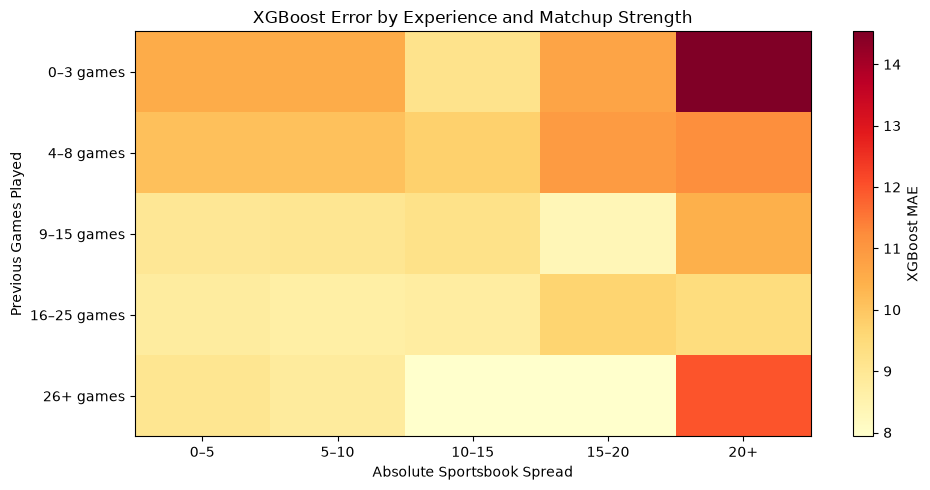

In [24]:
# Pivot into a matrix for visualization.
heatmap_data = combined_slice.pivot_table(
    index="experience_group",
    columns="spread_group",
    values="xgb_abs_error",
    aggfunc="mean",
    observed=True
)

plt.figure(figsize=(10, 5))

plt.imshow(
    heatmap_data,
    cmap="YlOrRd",
    aspect="auto"
)

plt.colorbar(label="XGBoost MAE")

plt.xticks(
    range(len(heatmap_data.columns)),
    heatmap_data.columns.astype(str)
)

plt.yticks(
    range(len(heatmap_data.index)),
    heatmap_data.index.astype(str)
)

plt.xlabel("Absolute Sportsbook Spread")
plt.ylabel("Previous Games Played")
plt.title("XGBoost Error by Experience and Matchup Strength")

plt.tight_layout()
plt.show()

In [25]:
heavy = matchup_df[
    matchup_df["absolute_spread"] >= 20
].copy()

# Positive market margin means home team is favored.
# Negative means away team is favored.
favorite_sign = np.sign(
    heavy[MARKET].to_numpy()
)

actual_favorite_margin = (
    heavy[TARGET].to_numpy() * favorite_sign
)

xgb_favorite_margin = (
    heavy["xgb_prediction"].to_numpy() * favorite_sign
)

market_favorite_margin = (
    heavy[MARKET].to_numpy() * favorite_sign
)

print(
    "Average actual favorite margin:",
    actual_favorite_margin.mean()
)

print(
    "Average XGBoost favorite margin:",
    xgb_favorite_margin.mean()
)

print(
    "Average sportsbook favorite margin:",
    market_favorite_margin.mean()
)

print(
    "XGBoost favorite-oriented signed error:",
    (actual_favorite_margin - xgb_favorite_margin).mean()
)

Average actual favorite margin: 27.229007633587788
Average XGBoost favorite margin: 21.89971049459836
Average sportsbook favorite margin: 27.137949836423118
XGBoost favorite-oriented signed error: 5.329297138989427


In [26]:
# Examine late-season games with large market spreads.
late_blowouts = combined_slice[
    (combined_slice["avg_games_played"] >= 26)
    & (combined_slice["absolute_spread"] >= 20)
].copy()

late_blowouts["month"] = pd.to_datetime(
    late_blowouts["date"]
).dt.month

# Check when these games occurred.
display(
    late_blowouts.groupby("month")
    .agg(
        Games=("xgb_abs_error", "size"),
        XGBoost_MAE=("xgb_abs_error", "mean"),
        Sportsbook_MAE=("market_abs_error", "mean")
    ).round(3)
)

,Games,XGBoost_MAE,Sportsbook_MAE
month,,,
2,9,10.206,9.056
3,28,11.751,11.625


In [27]:
heavy = matchup_df[
    matchup_df["absolute_spread"] >= 20
].copy()

# Express margins from the favorite's perspective.
favorite_sign = np.sign(heavy[MARKET].to_numpy())

actual_favorite_margin = (
    heavy[TARGET].to_numpy() * favorite_sign
)

xgb_favorite_margin = (
    heavy["xgb_prediction"].to_numpy() * favorite_sign
)

market_favorite_margin = (
    heavy[MARKET].to_numpy() * favorite_sign
)

print("Actual favorite margin:", actual_favorite_margin.mean())
print("XGBoost predicted margin:", xgb_favorite_margin.mean())
print("Sportsbook predicted margin:", market_favorite_margin.mean())

print(
    "XGBoost favorite-oriented signed error:",
    (actual_favorite_margin - xgb_favorite_margin).mean()
)

Actual favorite margin: 27.229007633587788
XGBoost predicted margin: 21.89971049459836
Sportsbook predicted margin: 27.137949836423118
XGBoost favorite-oriented signed error: 5.329297138989427


In [28]:
import numpy as np
import pandas as pd

def paired_mae_improvement(df):
    """
    Positive values mean XGBoost has lower MAE than Ridge.
    """
    ridge_error = (
        df[TARGET] - df["ridge_prediction"]
    ).abs()

    xgb_error = (
        df[TARGET] - df["xgb_prediction"]
    ).abs()

    return (ridge_error - xgb_error).to_numpy()


# All 11,514 test games
all_improvements = paired_mae_improvement(test_df)

# Only the 11,161 games with sportsbook lines
market_improvements = paired_mae_improvement(market_test)

print(
    "All-games MAE improvement:",
    round(all_improvements.mean(), 4)
)

print(
    "Market-games MAE improvement:",
    round(market_improvements.mean(), 4)
)

All-games MAE improvement: 0.1345
Market-games MAE improvement: 0.1376


In [29]:
def paired_bootstrap_ci(improvements, n_boot=5000, seed=42):
    """
    Bootstrap confidence interval for the mean
    paired MAE improvement.

    Positive improvement favors XGBoost.
    """
    rng = np.random.default_rng(seed)

    improvements = np.asarray(improvements)

    boot_means = np.empty(n_boot)

    for i in range(n_boot):
        sample = rng.choice(
            improvements,
            size=len(improvements),
            replace=True
        )

        boot_means[i] = sample.mean()

    lower, upper = np.percentile(
        boot_means, [2.5, 97.5]
    )

    return {
        "Mean Improvement": improvements.mean(),
        "CI Lower": lower,
        "CI Upper": upper
    }


all_ci = paired_bootstrap_ci(all_improvements)
market_ci = paired_bootstrap_ci(market_improvements)

ci_results = pd.DataFrame([
    {"Dataset": "All Test Games", **all_ci},
    {"Dataset": "Market-Covered Games", **market_ci}
])

display(ci_results.round(4))

,Dataset,Mean Improvement,CI Lower,CI Upper
0,All Test Games,0.1345,0.0845,0.1836
1,Market-Covered Games,0.1376,0.0881,0.1877


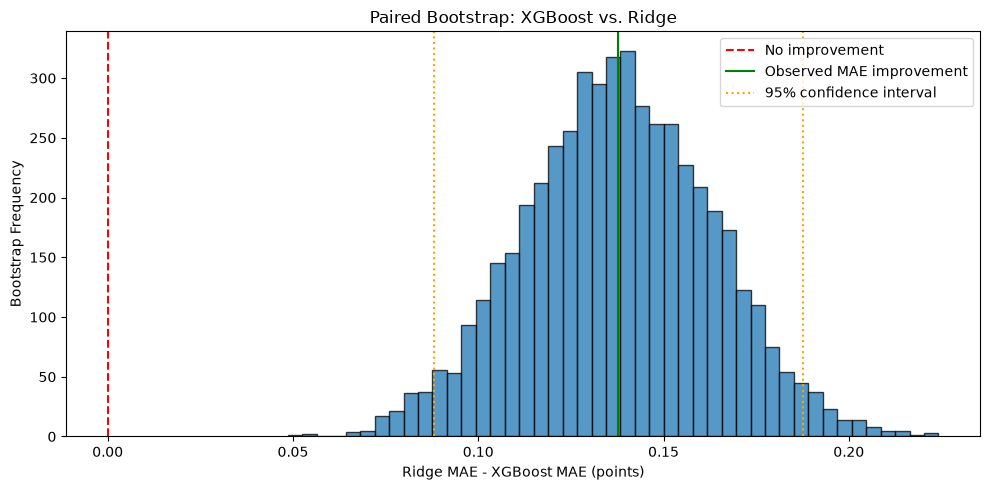

In [30]:
rng = np.random.default_rng(42)

boot_means = np.array([
    rng.choice(
        market_improvements,
        size=len(market_improvements),
        replace=True
    ).mean()
    for _ in range(5000)
])

plt.figure(figsize=(10, 5))

plt.hist(
    boot_means,
    bins=45,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="No improvement"
)

plt.axvline(
    market_improvements.mean(),
    color="green",
    linestyle="-",
    label="Observed MAE improvement"
)

plt.axvline(
    market_ci["CI Lower"],
    color="orange",
    linestyle=":"
)

plt.axvline(
    market_ci["CI Upper"],
    color="orange",
    linestyle=":",
    label="95% confidence interval"
)

plt.xlabel("Ridge MAE - XGBoost MAE (points)")
plt.ylabel("Bootstrap Frequency")
plt.title("Paired Bootstrap: XGBoost vs. Ridge")

plt.legend()
plt.tight_layout()
plt.show()

In [31]:
def date_clustered_bootstrap(df, n_boot=5000, seed=42):
    """
    Resample game dates with replacement, keeping
    all games from each sampled date together.
    """
    rng = np.random.default_rng(seed)

    data = df.copy()

    data["game_day"] = pd.to_datetime(
        data["date"], utc=True
    ).dt.date

    data["improvement"] = paired_mae_improvement(data)

    # One row per game date, storing total improvement
    # and number of games on that date.
    daily = data.groupby("game_day").agg(
        improvement_sum=("improvement", "sum"),
        games=("improvement", "size")
    )

    sums = daily["improvement_sum"].to_numpy()
    counts = daily["games"].to_numpy()

    n_days = len(daily)
    boot_means = np.empty(n_boot)

    for i in range(n_boot):
        sampled_days = rng.integers(
            0, n_days, size=n_days
        )

        boot_means[i] = (
            sums[sampled_days].sum()
            / counts[sampled_days].sum()
        )

    return {
        "Mean Improvement": data["improvement"].mean(),
        "CI Lower": np.percentile(boot_means, 2.5),
        "CI Upper": np.percentile(boot_means, 97.5),
        "Dates": n_days
    }


date_ci = date_clustered_bootstrap(market_test)

display(pd.DataFrame([date_ci]).round(4))

,Mean Improvement,CI Lower,CI Upper,Dates
0,0.1376,0.0827,0.1948,298
